# 01 Data: is the CRAS scan in the model's frame, and can the scanner positions be recovered?

**Slice.** The whole CRAS lab as a ~1 cm voxel cache of the scan (20.4 M points, with a scan class per point) and its IFC model, plus one room cut out of it; and the PC2Model UVigo sample (`real-indoor_modelling_3`).

**One question.** Is the CRAS scan already in the model's coordinate frame, so that scan and model can be compared directly, and can the 21 scanner positions be recovered from the shadows they leave on the floor?

Sections: (A) load, (B) frame check, (C) the room box notebooks 03 and 04 use, (D) scanner positions, (E) the PC2Model UVigo sample, then a short answer.
Terms (scan, model, element, clutter, scan class, scanner position) are defined in [CONTEXT.md](../CONTEXT.md).
All randomness is seeded. The notebook writes `01_cras_slice.json`, which notebooks 03 and 04 read.

In [1]:
import json, resource, time
from pathlib import Path

import ifcopenshell
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
import numpy as np
import open3d as o3d
import pye57
from scipy import ndimage as ndi
from scipy.signal import fftconvolve

from scan_vs_bim.load import load_e57, load_ifc_elements, merge_meshes

%config InlineBackend.figure_format = 'png'
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 100, "font.size": 9})

DATA = Path("..") / "data"
CACHE = DATA / "cras" / "cras_voxel_1cm.npz"
IFC = DATA / "cras" / "craslabbim.ifc"
UVIGO = DATA / "pc2model" / "real-indoor_modelling_3-ISPRS_indoor_modelling-UVigo"
SEED = 0
rng = np.random.default_rng(SEED)
o3d.utility.random.seed(SEED)  # Open3D's surface sampling
T0 = time.time()
RESULT = {}  # written to 01_cras_slice.json at the end


def peak_rss_gb():
    return resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1e9  # bytes on macOS


def apply(T, p):
    """Rigid transform T (4x4) applied to points p (n, 3); float32 in, float32 out."""
    return (p @ T[:3, :3].T.astype(np.float32) + T[:3, 3].astype(np.float32)).astype(np.float32)


def section(elements, axis, value):
    """Line segments where the plane `axis == value` cuts the elements' triangles.
    Returns (n, 2, 2): two end points in the other two axes (in x, y, z order)."""
    keep = [i for i in range(3) if i != axis]
    out = []
    for e in elements:
        v = e.vertices
        if v[:, axis].min() >= value or v[:, axis].max() <= value:
            continue
        tri = v[e.faces]
        s = tri[:, :, axis] - value
        P = np.full((len(tri), 2, 2), np.nan)
        count = np.zeros(len(tri), int)
        for i, j in ((0, 1), (1, 2), (2, 0)):
            idx = np.where(s[:, i] * s[:, j] < 0)[0]
            t = s[idx, i] / (s[idx, i] - s[idx, j])
            P[idx, count[idx]] = tri[idx, i][:, keep] + t[:, None] * (tri[idx, j][:, keep] - tri[idx, i][:, keep])
            count[idx] += 1
        out.append(P[count == 2])
    return np.concatenate(out) if out else np.zeros((0, 2, 2))


def draw_section(ax, elements, axis, value, color="k", lw=0.8):
    segs = section(elements, axis, value)
    ax.add_collection(LineCollection(segs, colors=color, linewidths=lw))


CLASS_NAMES = ["unassigned", "ceiling", "floor", "wall", "door", "window", "desk", "chair", "cabinet", "mobile cabinet",
               "shelf", "vents", "water tank", "bin", "box", "board", "computer", "screen", "printer", "vest", "switch",
               "paper dispenser", "alcohol dispenser", "cable", "phone", "robot", "water kettle", "stairs", "ladder",
               "oil heater", "divider", "hanger", "fan", "water dispenser"]
# scan classes the model also has an element for get a colour; all other classes are clutter
GROUP_COLOURS = {"unassigned": "#c8c8c8", "ceiling": "#8da0cb", "floor": "#66c2a5", "wall": "#fc8d62",
                 "door": "#e78ac3", "window": "#a6d854", "clutter": "#333333"}
CLASS_RGB = np.array([[int(GROUP_COLOURS[n if n in GROUP_COLOURS else "clutter"][k:k + 2], 16) / 255 for k in (1, 3, 5)]
                      for n in CLASS_NAMES], np.float32)


def legend_handles():
    return [plt.Line2D([], [], marker="o", ls="", ms=5, color=c, label=n) for n, c in GROUP_COLOURS.items()]

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


## A. Load the scan cache and the model

In [2]:
t = time.time()
ifc_elements_all = load_ifc_elements(IFC)  # tessellation first: it has the higher memory peak
print(f"IFC tessellated in {time.time() - t:.0f} s: {len(ifc_elements_all)} meshes, "
      f"{sum(len(e.faces) for e in ifc_elements_all):,} triangles")

# CONTEXT.md: furniture is not an element. The one IfcBuildingElementProxy is not in the element list either.
ELEMENT_CLASSES = ("IfcWallStandardCase", "IfcColumn", "IfcDoor", "IfcWindow", "IfcSlab", "IfcCovering", "IfcStairFlight")
elements = [e for e in ifc_elements_all if e.ifc_class in ELEMENT_CLASSES]
furniture = [e for e in ifc_elements_all if e.ifc_class == "IfcFurnishingElement"]
del ifc_elements_all
print("\nelements (verdicts are given to these):")
for c in ELEMENT_CLASSES:
    print(f"  {c:22s} {sum(e.ifc_class == c for e in elements):3d}")
print(f"furniture (clutter, no verdicts): {len(furniture)}")
all_v = np.concatenate([e.vertices for e in elements])
MODEL_MIN, MODEL_MAX = all_v.min(0), all_v.max(0)
del all_v
print("model bbox (elements) min", MODEL_MIN.round(2), "max", MODEL_MAX.round(2))

IFC tessellated in 221 s: 202 meshes, 1,197,070 triangles

elements (verdicts are given to these):
  IfcWallStandardCase     61
  IfcColumn               10
  IfcDoor                  6
  IfcWindow               44
  IfcSlab                  5
  IfcCovering              7
  IfcStairFlight           2
furniture (clutter, no verdicts): 66
model bbox (elements) min [-9.92 -4.53 -1.17] max [ 8.29 19.95  3.  ]


In [3]:
cache = np.load(CACHE)
meta = json.loads(str(cache["meta"]))
print("cache meta:")
for k, v in meta.items():
    print(f"  {k:15s} {v}")
xyz = cache["xyz"]  # scan frame, float32 (n, 3)
cls = cache["cls"]  # scan class per point
print(f"\n{len(xyz):,} points; scan bbox min {xyz.min(0).round(2)} max {xyz.max(0).round(2)}")
counts = np.bincount(cls, minlength=len(CLASS_NAMES))
print("\npoints per scan class (voxels, not area):")
for i in np.argsort(counts)[::-1]:
    print(f"  {i:2d} {CLASS_NAMES[i]:18s} {counts[i]:>10,d}  {counts[i] / len(cls):6.1%}")
print(f"peak RSS so far: {peak_rss_gb():.2f} GB")

cache meta:


  voxel_size      0.01
  member          CRASLAB_annotated.asc
  member_size     26752658348
  points_read     584701977
  points_declared 584701977
  points_kept     20404814
  extent_min      [0.013500000350177288, -4.184500217437744, -2.066499948501587]
  extent_max      [18.318500518798828, 20.274499893188477, 3.250499963760376]



20,404,814 points; scan bbox min [ 0.01 -4.18 -2.07] max [18.32 20.27  3.25]



points per scan class (voxels, not area):
   1 ceiling             4,866,625   23.9%
   0 unassigned          3,955,826   19.4%
   3 wall                3,051,354   15.0%
   2 floor               2,812,400   13.8%
  14 box                 1,071,566    5.3%
   6 desk                  990,383    4.9%
   8 cabinet               700,522    3.4%
   5 window                658,513    3.2%
   4 door                  445,336    2.2%
   7 chair                 320,568    1.6%
  12 water tank            266,316    1.3%
  11 vents                 253,607    1.2%
  10 shelf                 190,766    0.9%
  30 divider               179,539    0.9%
  25 robot                 157,380    0.8%
  15 board                 112,112    0.5%
  17 screen                 75,698    0.4%
  31 hanger                 52,358    0.3%
  13 bin                    42,642    0.2%
  27 stairs                 42,074    0.2%
  18 printer                27,607    0.1%
  23 cable                  21,082    0.1%
  33 water 

Counts are 1 cm voxels (one point kept per voxel), so a class's count is roughly its surface area in cm-squared, not how many laser returns it had.
The extents already hint at the answer to B: the scan spans x 0.0 to 18.3 m while the model's elements span x -9.9 to 8.3 m.

## B. Frame check: is the scan in the model's frame?

Measure: the **unsigned distance from scan points of scan class 3 (wall) to the nearest model wall or column surface**, for a seeded sample of 200 000 wall points.
This is the right number because both the scan and the model have these surfaces: if the frame is shared, the distances are small, whatever the clutter.

Verdict thresholds on the **median** distance. These are my judgement calls, not from a standard (the tolerance for later notebooks, USIBD LOA30 at 15 mm, applies to element verdicts, not to this question):
* **in frame**: median < 5 cm. Scan and model can be compared as they are.
* **near**: median < 50 cm. A small rigid correction (ICP) will close it.
* **far off**: otherwise. The scan needs a coarse registration first.

In [4]:
wall_model = [e for e in elements if e.ifc_class in ("IfcWallStandardCase", "IfcColumn")]
scene = o3d.t.geometry.RaycastingScene()
scene.add_triangles(o3d.t.geometry.TriangleMesh.from_legacy(merge_meshes(wall_model)))


def dist_to_model_walls(p):
    return scene.compute_distance(o3d.core.Tensor(np.ascontiguousarray(p, dtype=np.float32))).numpy()


wall_idx = np.flatnonzero(cls == 3)
wall_sample = xyz[rng.choice(wall_idx, 200_000, replace=False)]
d_unaligned = dist_to_model_walls(wall_sample)


def dist_stats(d):
    return {"median": float(np.median(d)), "p25": float(np.percentile(d, 25)), "p75": float(np.percentile(d, 75)),
            "p90": float(np.percentile(d, 90)), "p99": float(np.percentile(d, 99))}


print("scan wall points as delivered (scan frame = model frame assumed):")
print({k: f"{v:.3f} m" for k, v in dist_stats(d_unaligned).items()})

scan wall points as delivered (scan frame = model frame assumed):
{'median': '2.679 m', 'p25': '0.709 m', 'p75': '6.845 m', 'p90': '9.587 m', 'p99': '9.785 m'}


The raw median is metres, so the scan is **not in the model's frame as delivered**. Before calling it far off, find out what the offset is, so the answer carries a number.

The estimate has three steps. Each is cheap and only needs the model and a few scan classes:
1. **Coarse xy shift**: cross-correlate a 5 cm occupancy raster of scan wall points with one of points sampled on the model walls and columns (FFT, whole plan).
2. **z shift**: scan floor level (mode of the floor-class heights) to the top of the model's largest slab.
3. **Rigid ICP, point-to-plane**, at 0.3, 0.15, 0.05 m correspondence distance, from scan classes wall, floor and ceiling (oracle labels, used here only to find the frame) to points sampled on model walls, columns, slabs and coverings.

In [5]:
# 1. coarse xy shift from the occupancy of wall footprints
surf = merge_meshes([e for e in elements if e.ifc_class in ("IfcWallStandardCase", "IfcColumn", "IfcSlab", "IfcCovering")])
model_pts = surf.sample_points_uniformly(600_000, use_triangle_normal=True)
wall_model_pts = np.asarray(merge_meshes(wall_model).sample_points_uniformly(300_000).points)

CELL_COARSE = 0.05
lo_c = np.array([-25.0, -15.0])
shape_c = (int(60 / CELL_COARSE), int(50 / CELL_COARSE))


def raster(p):
    ij = np.floor((p[:, :2] - lo_c) / CELL_COARSE).astype(int)
    ok = (ij >= 0).all(1) & (ij[:, 0] < shape_c[0]) & (ij[:, 1] < shape_c[1])
    r = np.zeros(shape_c, np.float32)
    r[ij[ok, 0], ij[ok, 1]] = 1
    return r


corr = np.fft.irfft2(np.conj(np.fft.rfft2(raster(wall_sample))) * np.fft.rfft2(raster(wall_model_pts)), s=shape_c)
k = np.array(np.unravel_index(corr.argmax(), shape_c))
shift_xy = np.where(k * CELL_COARSE > shape_c[0] * CELL_COARSE / 2, k - np.array(shape_c), k) * CELL_COARSE  # model = scan + shift
print(f"coarse xy shift (model = scan + shift): {shift_xy.round(2)} m; correlation peak {corr.max():.0f} vs median {np.median(corr):.0f}")

# 2. z shift: scan floor level to the top of the largest slab
fz = xyz[cls == 2, 2]
h, edges = np.histogram(fz, bins=np.arange(fz.min(), fz.max() + 0.004, 0.002))
scan_floor_z = float(edges[h.argmax()] + 0.001)
slab = max((e for e in elements if e.ifc_class == "IfcSlab"), key=lambda e: np.ptp(e.vertices[:, 0]) * np.ptp(e.vertices[:, 1]))
model_floor_z = float(slab.vertices[:, 2].max())
shift_z = model_floor_z - scan_floor_z
print(f"scan floor z {scan_floor_z:.3f} m, model slab top z {model_floor_z:.3f} m -> z shift {shift_z:.3f} m")
del fz

coarse xy shift (model = scan + shift): [-9.9 -0.2] m; correlation peak 2505 vs median 13


scan floor z -1.150 m, model slab top z 0.100 m -> z shift 1.250 m


In [6]:
# 3. point-to-plane ICP (scan -> model)
pick = lambda c, n: xyz[rng.choice(np.flatnonzero(cls == c), n, replace=False)].astype(np.float64)
src = o3d.geometry.PointCloud(o3d.utility.Vector3dVector(np.concatenate([pick(3, 150_000), pick(2, 75_000), pick(1, 75_000)])))
T = np.eye(4)
T[:3, 3] = [shift_xy[0], shift_xy[1], shift_z]
T_translation_only = T.copy()
est = o3d.pipelines.registration.TransformationEstimationPointToPlane()
for thr in (0.3, 0.15, 0.05):
    r = o3d.pipelines.registration.registration_icp(
        src, model_pts, thr, T, est, o3d.pipelines.registration.ICPConvergenceCriteria(max_iteration=60))
    T = r.transformation
    print(f"ICP at {thr:4.2f} m: fitness {r.fitness:.2f}, inlier RMSE {r.inlier_rmse * 100:.1f} cm")
R = T[:3, :3]
yaw_deg = float(np.degrees(np.arctan2(R[1, 0], R[0, 0])))
tilt_deg = float(np.degrees(np.arccos(np.clip(R[2, 2], -1, 1))))
print(f"\nscan -> model: translation {T[:3, 3].round(3)} m, yaw {yaw_deg:.2f} deg, tilt {tilt_deg:.2f} deg")
print("(the translation is where the scan origin lands; a yaw of about 1 deg moves a point 10 m from the origin by about 16 cm)")
del src, model_pts, surf

ICP at 0.30 m: fitness 1.00, inlier RMSE 5.4 cm


ICP at 0.15 m: fitness 0.98, inlier RMSE 4.8 cm


ICP at 0.05 m: fitness 0.70, inlier RMSE 3.1 cm

scan -> model: translation [-9.817 -0.427  1.258] m, yaw 0.91 deg, tilt 0.02 deg
(the translation is where the scan origin lands; a yaw of about 1 deg moves a point 10 m from the origin by about 16 cm)


In [7]:
d_translation = dist_to_model_walls(apply(T_translation_only, wall_sample))
d_icp = dist_to_model_walls(apply(T, wall_sample))
stats = {"as delivered": dist_stats(d_unaligned), "translation only": dist_stats(d_translation), "translation + ICP": dist_stats(d_icp)}
print(f"{'':20s}" + "".join(f"{k:>9s}" for k in ("median", "p25", "p75", "p90", "p99")) + "   (metres, wall-class scan points to model walls)")
for name, s in stats.items():
    print(f"{name:20s}" + "".join(f"{s[k]:9.3f}" for k in ("median", "p25", "p75", "p90", "p99")))
print(f"after ICP: {np.mean(d_icp <= 0.015):.0%} of wall points within 1.5 cm of a model wall, {np.mean(d_icp <= 0.05):.0%} within 5 cm")

med = stats["as delivered"]["median"]
frame_answer = "in frame" if med < 0.05 else "near" if med < 0.5 else "far off"
print(f"\nFRAME ANSWER (median {med:.2f} m as delivered): {frame_answer}")
assert frame_answer == "far off"  # the as-delivered median is metres; the text below says so
assert stats["translation + ICP"]["median"] < 0.05, "estimated transform does not bring the scan into the model's frame"
RESULT["frame"] = {
    "answer": frame_answer,
    "thresholds_m": {"in_frame_median_below": 0.05, "near_median_below": 0.5},
    "median_distance_m": {k: v["median"] for k, v in stats.items()},
    "p90_distance_m": {k: v["p90"] for k, v in stats.items()},
    "scan_to_model_4x4": T.tolist(),
    "translation_m": T[:3, 3].tolist(), "yaw_deg": yaw_deg, "tilt_deg": tilt_deg,
    "note": "Estimated, not given: coarse FFT shift, z from floor/slab, point-to-plane ICP on scan classes wall/floor/ceiling. Apply to scan points to get the model frame.",
}

                       median      p25      p75      p90      p99   (metres, wall-class scan points to model walls)
as delivered            2.679    0.709    6.845    9.587    9.785
translation only        0.044    0.021    0.105    0.153    0.488
translation + ICP       0.014    0.006    0.046    0.084    0.481
after ICP: 52% of wall points within 1.5 cm of a model wall, 77% within 5 cm

FRAME ANSWER (median 2.68 m as delivered): far off


### Frame check: figures

Left: the scan and the model drawn together exactly as delivered. Right: the same points after the estimated rigid transform.
Both panels show the scan points in a 0.5 m slab at chest height (the same points in both) and the model's cut at z = 1.15 m (black lines; walls, columns, doors, stair; windows sit higher and do not show). Orange points are scan class wall.

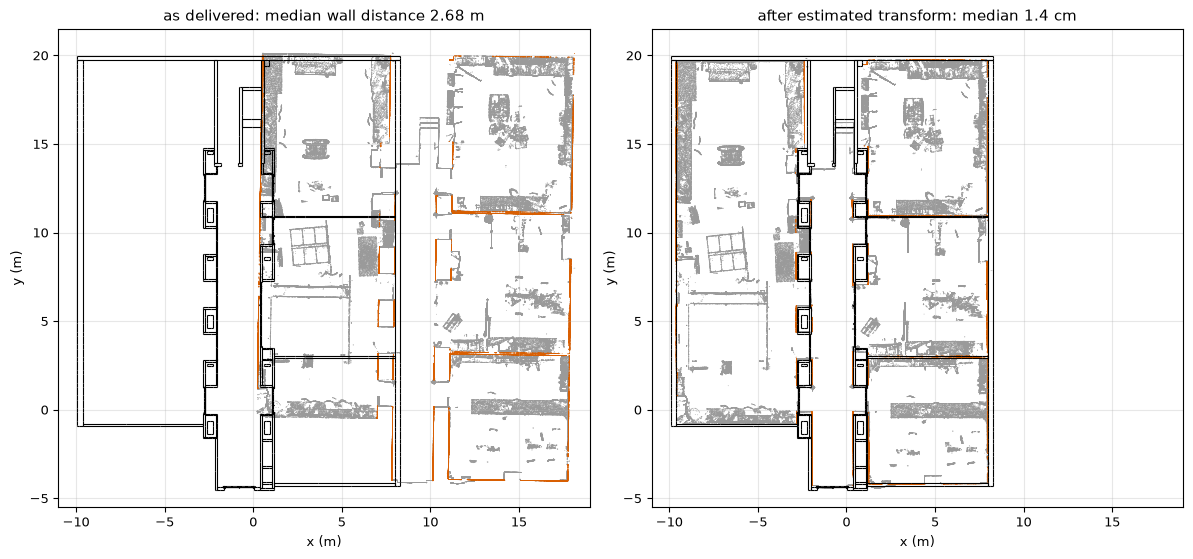

In [8]:
pm = np.empty_like(xyz)  # the scan in the model frame (estimated transform T)
for i in range(0, len(xyz), 4_000_000):
    pm[i:i + 4_000_000] = apply(T, xyz[i:i + 4_000_000])
slab_idx = np.flatnonzero((pm[:, 2] > 0.9) & (pm[:, 2] < 1.4))
plan_idx = np.sort(rng.choice(slab_idx, 300_000, replace=False))
wall_c, other_c = "#d95f02", "#9a9a9a"
plan_colour = np.where(cls[plan_idx] == 3, wall_c, other_c)

fig, axs = plt.subplots(1, 2, figsize=(12, 6.6))
for ax, P, title in ((axs[0], xyz, f"as delivered: median wall distance {stats['as delivered']['median']:.2f} m"),
                     (axs[1], pm, f"after estimated transform: median {stats['translation + ICP']['median'] * 100:.1f} cm")):
    ax.scatter(P[plan_idx, 0], P[plan_idx, 1], s=0.3, c=plan_colour, linewidths=0, rasterized=True)
    draw_section(ax, elements, 2, 1.15)
    ax.set_xlim(-11, 19); ax.set_ylim(-5.5, 21.5)
    ax.set_aspect("equal"); ax.set_title(title); ax.set_xlabel("x (m)"); ax.set_ylabel("y (m)"); ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

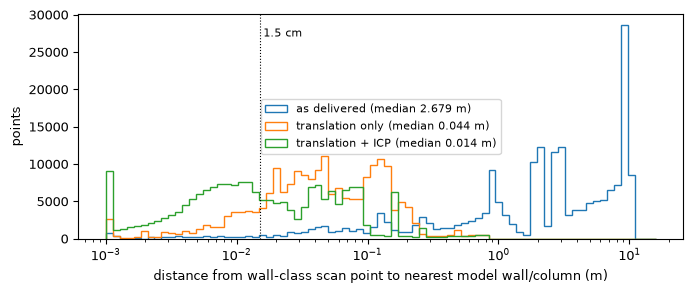

In [9]:
fig, ax = plt.subplots(figsize=(7, 3))
bins = np.logspace(-3, 1.2, 80)
for name, d in (("as delivered", d_unaligned), ("translation only", d_translation), ("translation + ICP", d_icp)):
    ax.hist(np.clip(d, bins[0], None), bins=bins, histtype="step", label=f"{name} (median {np.median(d):.3f} m)")
ax.set_xscale("log"); ax.set_xlabel("distance from wall-class scan point to nearest model wall/column (m)"); ax.set_ylabel("points")
ax.axvline(0.015, c="k", ls=":", lw=0.8); ax.text(0.016, ax.get_ylim()[1] * 0.9, "1.5 cm", fontsize=8)
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

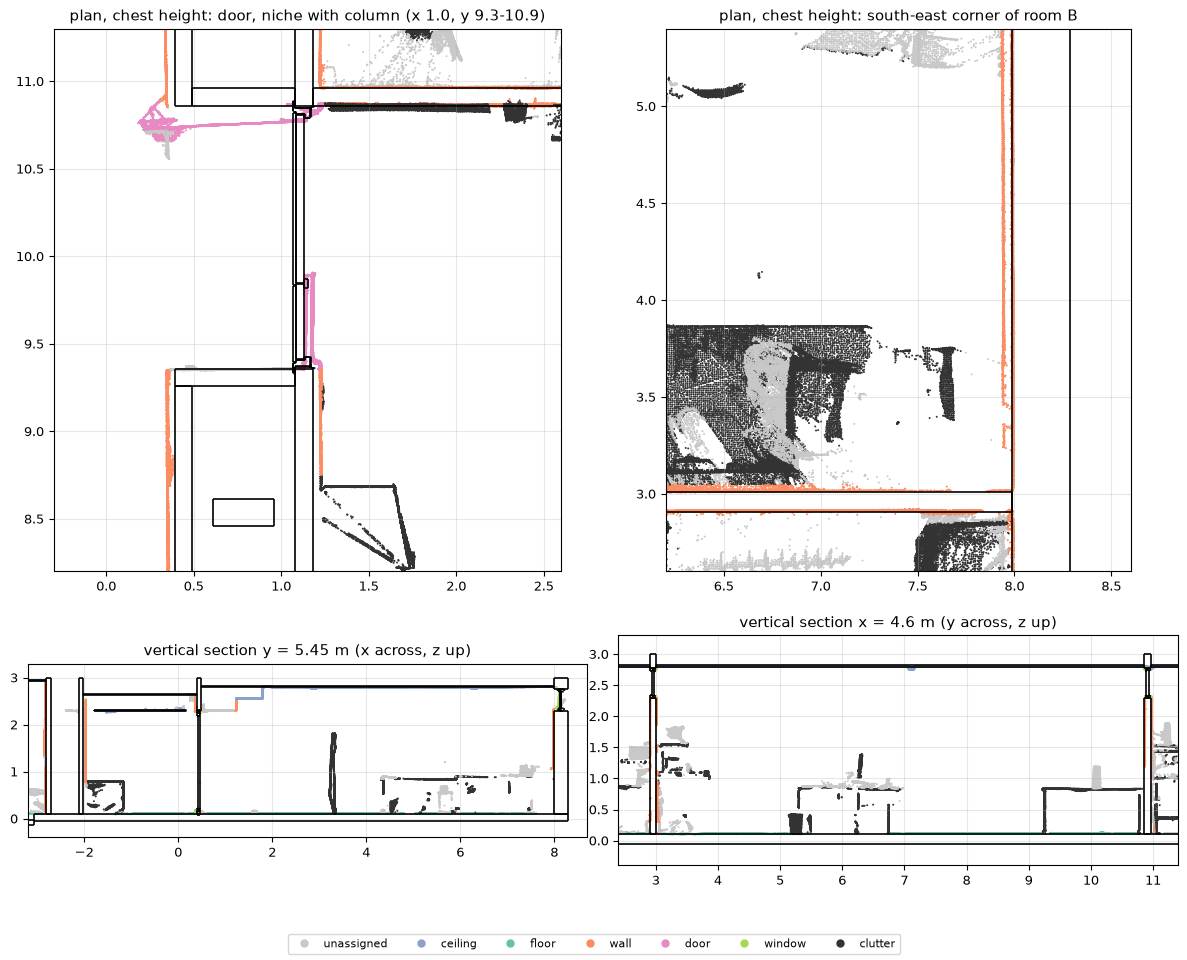

peak RSS so far: 1.30 GB


In [10]:
# close-ups after the estimated transform: two plan views and two vertical sections, all scan classes coloured
def close_up(ax, region, axis=None, value=None, slab=0.03):
    """Plan view (axis=None) of the chest-height slab, or a vertical section: scan points within +-slab of the plane axis == value."""
    if axis is None:
        idx = slab_idx
        a, b = 0, 1
    else:
        idx = np.flatnonzero(np.abs(pm[:, axis] - value) < slab)
        a, b = (1, 2) if axis == 0 else (0, 2)
    p = pm[idx]
    keep = (p[:, a] > region[0]) & (p[:, a] < region[1]) & (p[:, b] > region[2]) & (p[:, b] < region[3])
    idx = idx[keep]
    idx = idx[np.argsort(pm[idx, 2])]  # higher points drawn last
    ax.scatter(pm[idx, a], pm[idx, b], s=2, c=CLASS_RGB[cls[idx]], linewidths=0, rasterized=True)
    draw_section(ax, elements, 2 if axis is None else axis, 1.15 if axis is None else value, lw=1.2)
    ax.set_xlim(region[0], region[1]); ax.set_ylim(region[2], region[3]); ax.set_aspect("equal"); ax.grid(alpha=0.3)
    return a, b


fig, axs = plt.subplots(2, 2, figsize=(12, 9.6), gridspec_kw={"height_ratios": [1, 0.6]})
close_up(axs[0, 0], (-0.3, 2.6, 8.2, 11.3)); axs[0, 0].set_title("plan, chest height: door, niche with column (x 1.0, y 9.3-10.9)")
close_up(axs[0, 1], (6.2, 8.6, 2.6, 5.4)); axs[0, 1].set_title("plan, chest height: south-east corner of room B")
close_up(axs[1, 0], (-3.2, 8.7, -0.4, 3.3), axis=1, value=5.45, slab=0.05); axs[1, 0].set_title("vertical section y = 5.45 m (x across, z up)")
close_up(axs[1, 1], (2.4, 11.4, -0.4, 3.3), axis=0, value=4.6, slab=0.05); axs[1, 1].set_title("vertical section x = 4.6 m (y across, z up)")
fig.legend(handles=legend_handles(), fontsize=8, loc="lower center", ncol=7)
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.show()
print(f"peak RSS so far: {peak_rss_gb():.2f} GB")

## C. The room box

The IFC has no `IfcSpace`, so a room is a hand-picked box. From the aligned plan (figure above) the room I picked is the middle of the three large rooms on the east side of the building ("room B"):
* bounded on all four sides by model walls: south (y 2.9), north (y 11.0), east (x 8.0 to 8.3), and on the west a thin wall with glazing (x 0.4) next to a wall with a door (x 1.1, y 9.3 to 10.9);
* it has that door, windows in all four walls (the listing below counts them), and a column in a niche at the west wall;
* its floor is full of clutter (desks, boxes, shelves), which is what notebook 03 has to see through;
* about 8 x 8 m, the same size as its two neighbours, so notebook 03 stays small.

The box is in the **model frame** and is a little larger than the room's inner faces so that the bounding walls lie inside it. Nothing else decides which element is "in the room": an element counts if its bounding box touches the box.
(Room C, to the north, is bounded by walls only on three sides and opens into the stair lobby, so it has no clean box.)

In [11]:
ROOM_BOX = dict(xmin=0.38, xmax=8.30, ymin=2.90, ymax=10.97, zmin=-0.10, zmax=3.05)  # model frame, metres
box_lo = np.array([ROOM_BOX[k] for k in ("xmin", "ymin", "zmin")])
box_hi = np.array([ROOM_BOX[k] for k in ("xmax", "ymax", "zmax")])

room_idx = np.flatnonzero(((pm >= box_lo) & (pm <= box_hi)).all(1))
print(f"scan points in the room box: {len(room_idx):,} of {len(pm):,} ({len(room_idx) / len(pm):.1%})")
room_counts = np.bincount(cls[room_idx], minlength=len(CLASS_NAMES))
structure = room_counts[1:6].sum()
print(f"  structure classes (ceiling, floor, wall, door, window): {structure:,} ({structure / len(room_idx):.0%}); "
      f"clutter classes (6-33): {room_counts[6:].sum():,} ({room_counts[6:].sum() / len(room_idx):.0%}); unassigned: {room_counts[0]:,}")
for i in np.argsort(room_counts)[::-1][:10]:
    print(f"    {i:2d} {CLASS_NAMES[i]:16s} {room_counts[i]:>9,d}")

el_lo = np.array([e.vertices.min(0) for e in elements])
el_hi = np.array([e.vertices.max(0) for e in elements])
touches = ((el_lo < box_hi) & (el_hi > box_lo)).all(1)
inside = ((el_lo >= box_lo - 1e-3) & (el_hi <= box_hi + 1e-3)).all(1)
room_elements = [(e, bool(i)) for e, t, i in zip(elements, touches, inside) if t]
f_lo = np.array([e.vertices.min(0) for e in furniture]); f_hi = np.array([e.vertices.max(0) for e in furniture])
n_furniture_in_room = int(((f_lo < box_hi) & (f_hi > box_lo)).all(1).sum())

ifc_file = ifcopenshell.open(str(IFC))
print(f"\nmodel elements touching the box: {len(room_elements)} ({sum(i for _, i in room_elements)} entirely inside, "
      f"the rest cross a box face); modelled furniture touching the box (not elements): {n_furniture_in_room}")
print(f"{'IFC class':22s} {'GlobalId':24s} {'name':42s} where")
for e, i in sorted(room_elements, key=lambda t: (t[0].ifc_class, t[0].global_id)):
    print(f"{e.ifc_class:22s} {e.global_id:24s} {str(ifc_file.by_guid(e.global_id).Name)[:42]:42s} {'inside' if i else 'crosses the box'}")
del ifc_file

room_classes = [e.ifc_class for e, _ in room_elements]
assert len(room_idx) > 100_000
assert room_classes.count("IfcWallStandardCase") >= 4 and "IfcDoor" in room_classes and room_classes.count("IfcWindow") >= 5, "room is not bounded by walls with a door and windows"
RESULT["room"] = {
    "box_model_frame": ROOM_BOX,
    "frame_note": "model frame; apply frame.scan_to_model_4x4 to scan points before cropping",
    "scan_points_in_box": int(len(room_idx)),
    "element_global_ids": [e.global_id for e, _ in sorted(room_elements, key=lambda t: (t[0].ifc_class, t[0].global_id))],
    "element_classes": {c: room_classes.count(c) for c in sorted(set(room_classes))},
}

scan points in the room box: 3,672,674 of 20,404,814 (18.0%)
  structure classes (ceiling, floor, wall, door, window): 2,284,302 (62%); clutter classes (6-33): 926,062 (25%); unassigned: 462,310
     1 ceiling            800,605
     3 wall               676,952
     2 floor              568,861
     0 unassigned         462,310
    30 divider            179,539
     6 desk               165,416
     8 cabinet            164,845
     5 window             155,652
    14 box                125,960
     4 door                82,232



model elements touching the box: 35 (24 entirely inside, the rest cross a box face); modelled furniture touching the box (not elements): 21
IFC class              GlobalId                 name                                       where
IfcColumn              054HMVvnL1EOSZl$bniLeG   M_Concrete-Rectangular-Column:150 x 350mm: inside
IfcCovering            2unE$VYSL2OPIL$6LYYccT   Compound Ceiling:Forro de gesso:1428995    inside
IfcCovering            2unE$VYSL2OPIL$6LYYcpM   Compound Ceiling:Forro de gesso:1428296    crosses the box
IfcCovering            2unE$VYSL2OPIL$6LYYd$b   Compound Ceiling:Forro de gesso:1431675    crosses the box
IfcCovering            2unE$VYSL2OPIL$6LYYdVk   Compound Ceiling:Forro de gesso:1429616    crosses the box
IfcCovering            33gtcvddH7cec8$WOT4fKs   Forros 1:Forros 1:1537527                  crosses the box
IfcDoor                0WU0DUvgT6tu4IXFc9kNX5   Doors_Door-sets_Swedoor_JELD-WEN_Exterior_ inside
IfcSlab                3XP_HdJcfD9xJPuaO

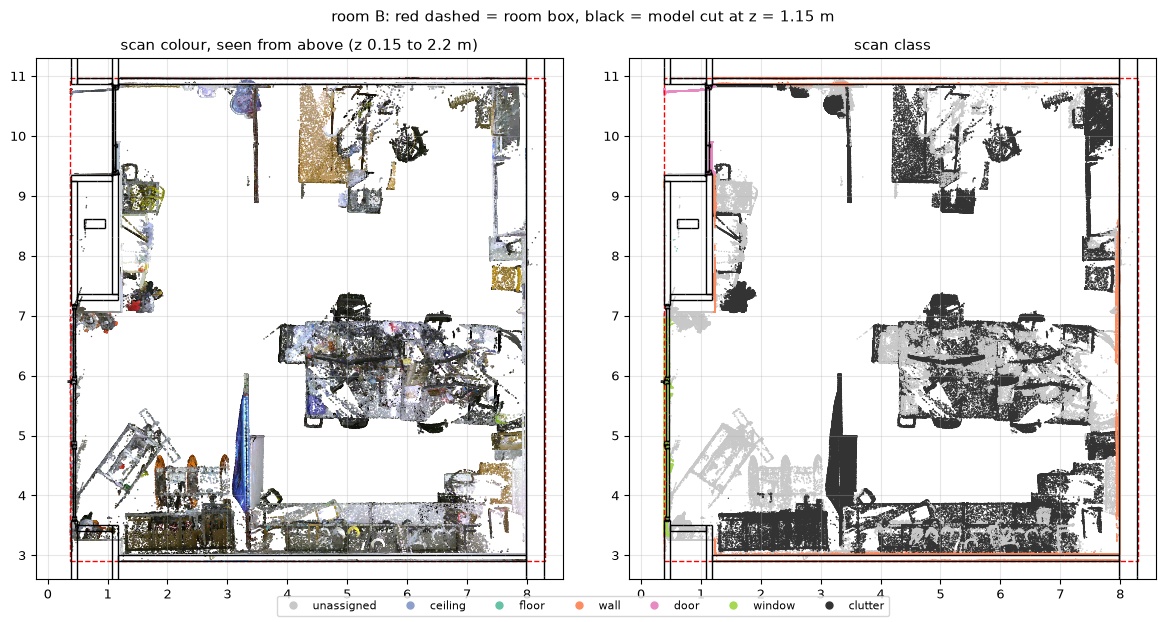

In [12]:
# the room seen from above: scan colours, and scan classes; model section at z = 1.15 m in black
rgb_room = cache["rgb"][room_idx]
visible = np.flatnonzero((pm[room_idx, 2] > 0.15) & (pm[room_idx, 2] < 2.2))  # between floor and ceiling covering
pick_v = np.sort(rng.choice(visible, min(500_000, len(visible)), replace=False))
pick_v = pick_v[np.argsort(pm[room_idx[pick_v], 2])]  # higher points drawn last
P = pm[room_idx[pick_v]]
fig, axs = plt.subplots(1, 2, figsize=(12, 6.2))
axs[0].scatter(P[:, 0], P[:, 1], s=1, c=rgb_room[pick_v] / 255, linewidths=0, rasterized=True)
axs[1].scatter(P[:, 0], P[:, 1], s=1, c=CLASS_RGB[cls[room_idx[pick_v]]], linewidths=0, rasterized=True)
for ax, title in zip(axs, ("scan colour, seen from above (z 0.15 to 2.2 m)", "scan class")):
    draw_section(ax, [e for e, _ in room_elements], 2, 1.15, lw=1.0)
    ax.add_patch(plt.Rectangle((box_lo[0], box_lo[1]), box_hi[0] - box_lo[0], box_hi[1] - box_lo[1], fill=False, ec="r", ls="--", lw=1))
    ax.set_xlim(-0.2, 8.6); ax.set_ylim(2.6, 11.3); ax.set_aspect("equal"); ax.set_title(title); ax.grid(alpha=0.3)
fig.legend(handles=legend_handles(), fontsize=8, loc="lower center", ncol=7)
fig.suptitle("room B: red dashed = room box, black = model cut at z = 1.15 m")
plt.tight_layout(rect=(0, 0.04, 1, 0.97)); plt.show()
del rgb_room, P

## D. Scanner positions: can the 21 be recovered from the floor?

**Idea.** A terrestrial scanner cannot see straight down. Its blind spot is a cone below the instrument, so the floor under each scanner position is missing from that scan. In a merged scan the hole is only left if no other scanner position saw that floor either. That should give a clean round hole, easy to tell from the irregular shadows of furniture.

**Detector.** On the floor-class (class 2) points, build a 2 cm occupancy map, then look for a disk of radius 0.8 to 1.4 m that is (1) at least 97% empty and (2) whose boundary is traced by the edge of the floor: the score is the fraction of the circle's circumference that coincides with floor cells that touch an empty cell (a Hough-style vote, done with FFT convolutions). A hole half hidden by a desk still scores about 0.5 to 0.7; furniture shadows and the edges of big empty areas score below 0.4.

**Validate first on a synthetic floor with known holes** (TDD check): a 12 x 9 m floor at 1 cm point spacing with 3 shadow holes (radius 1.0 to 1.2 m, one of them half hidden by a desk-shaped gap), a furniture shadow, a small round hole (a bin, radius 0.2 m), an unscanned strip along a wall and 3% random speckle. The detector must find the 3 holes within 5 cm and report nothing else above the acceptance score of 0.5. The acceptance score is chosen from this test (true holes 0.67 to 0.91, the one false candidate 0.35), not from the real data.

In [13]:
CELL = 0.02  # m


def occupancy(xy, cell=CELL, margin=0.5):
    """Point count per cell. Returns (counts[nx, ny], lower-left corner)."""
    lo = xy.min(0) - margin
    shape = np.ceil((xy.max(0) + margin - lo) / cell).astype(int)
    ij = np.floor((xy - lo) / cell).astype(int)
    H = np.bincount(ij[:, 0] * shape[1] + ij[:, 1], minlength=shape[0] * shape[1]).reshape(shape)
    return H, lo


def find_scanner_holes(H, lo, cell=CELL, radii=np.arange(0.8, 1.4001, 0.05), min_empty=0.97, min_votes=0.25, min_sep=1.5):
    """Round empty disks enclosed by floor. Returns candidates (x, y, r, votes, empty), best first."""
    floor = ndi.binary_closing(H > 0)  # close 1-cell speckle
    edge = (floor & ndi.binary_dilation(~floor)).astype(np.float32)  # floor cells touching an empty cell
    floor = floor.astype(np.float32)
    best_v, best_r, best_e = (np.zeros(H.shape, np.float32) for _ in range(3))
    for r in radii:
        n = int(np.ceil((r + 0.1) / cell))
        yy, xx = np.mgrid[-n:n + 1, -n:n + 1] * cell
        rr = np.hypot(xx, yy)
        ring = (np.abs(rr - r) <= 0.03).astype(np.float32)
        disk = (rr <= r - 0.06).astype(np.float32)
        votes = fftconvolve(edge, ring, mode="same") / (2 * np.pi * r / cell)  # 1.0 = whole circle traced
        empty = fftconvolve(1 - floor, disk, mode="same") / disk.sum()
        votes = np.where(empty >= min_empty, votes, 0)
        better = votes > best_v
        best_v[better], best_r[better], best_e[better] = votes[better], r, empty[better]
    found, work, k = [], best_v.copy(), int(min_sep / cell)
    while True:
        i = np.unravel_index(work.argmax(), work.shape)
        if work[i] < min_votes:
            return found
        found.append(dict(x=float(lo[0] + (i[0] + .5) * cell), y=float(lo[1] + (i[1] + .5) * cell),
                          r=float(best_r[i]), votes=float(work[i]), empty=float(best_e[i])))
        work[max(0, i[0] - k):i[0] + k, max(0, i[1] - k):i[1] + k] = 0  # non-maximum suppression


ACCEPT = 0.5  # minimum vote fraction to count a hole as a scanner position

# synthetic floor with known holes
rs = np.random.default_rng(SEED)
gx, gy = np.meshgrid(np.arange(0, 12, 0.01), np.arange(0, 9, 0.01), indexing="ij")
syn = np.stack([gx.ravel(), gy.ravel()], 1) + rs.uniform(-0.005, 0.005, (gx.size, 2))  # 1 cm spacing with jitter
TRUE_HOLES = [(3.0, 3.0, 1.10), (8.5, 6.0, 1.00), (9.0, 2.0, 1.20)]
gone = np.zeros(len(syn), bool)
for hx, hy, hr in TRUE_HOLES:
    gone |= np.hypot(syn[:, 0] - hx, syn[:, 1] - hy) < hr
gone |= (syn[:, 0] > 9.0) & (syn[:, 0] < 10.6) & (syn[:, 1] > 1.2) & (syn[:, 1] < 3.0)  # desk hides the right half of hole 3
gone |= (syn[:, 0] > 5.0) & (syn[:, 0] < 6.5) & (syn[:, 1] > 6.5) & (syn[:, 1] < 8.0)  # furniture shadow
gone |= np.hypot(syn[:, 0] - 6.0, syn[:, 1] - 2.0) < 0.2  # a bin: small round hole, not a scanner
gone |= (syn[:, 1] < 0.6) & (syn[:, 0] > 0.5) & (syn[:, 0] < 4.5)  # unscanned strip along a wall
gone |= rs.random(len(syn)) < 0.03  # speckle
syn = syn[~gone]

H_syn, lo_syn = occupancy(syn)
cand_syn = find_scanner_holes(H_syn, lo_syn)
accepted_syn = [c for c in cand_syn if c["votes"] >= ACCEPT]
print("synthetic floor, candidates:")
for c in cand_syn:
    print(f"  x {c['x']:.2f} y {c['y']:.2f} r {c['r']:.2f}  votes {c['votes']:.2f}  empty {c['empty']:.2f}  {'ACCEPTED' if c['votes'] >= ACCEPT else 'rejected'}")
assert len(accepted_syn) == len(TRUE_HOLES), f"expected {len(TRUE_HOLES)} holes, accepted {len(accepted_syn)}"
for hx, hy, hr in TRUE_HOLES:
    err = min(np.hypot(c["x"] - hx, c["y"] - hy) for c in accepted_syn)
    assert err < 0.05, f"hole at ({hx}, {hy}) missed by {err:.2f} m"
    assert min(abs(c["r"] - hr) for c in accepted_syn) <= 0.05 + 1e-9
print(f"synthetic check passed: all {len(TRUE_HOLES)} holes recovered within 5 cm and 5 cm of radius, nothing else accepted")

synthetic floor, candidates:
  x 2.99 y 3.01 r 1.10  votes 0.91  empty 1.00  ACCEPTED
  x 8.49 y 6.01 r 1.00  votes 0.90  empty 1.00  ACCEPTED
  x 9.01 y 2.01 r 1.20  votes 0.67  empty 1.00  ACCEPTED
  x 5.73 y 7.23 r 0.80  votes 0.35  empty 0.99  rejected
synthetic check passed: all 3 holes recovered within 5 cm and 5 cm of radius, nothing else accepted


### On the real floor

The floor map is built in the model frame (from the aligned scan) from all points of scan class 2, with the same detector and the same acceptance score.

In [14]:
t = time.time()
floor_xy = pm[cls == 2][:, :2].astype(np.float64)
H_floor, lo_floor = occupancy(floor_xy)
cand = find_scanner_holes(H_floor, lo_floor)
accepted = [c for c in cand if c["votes"] >= ACCEPT]
print(f"floor map: {H_floor.shape[0]} x {H_floor.shape[1]} cells of {CELL * 100:.0f} cm, {np.mean(H_floor > 0):.0%} of the cells in the bounding box hold floor points ({time.time() - t:.0f} s incl. detection)")
print(f"{len(cand)} candidates above vote 0.25 (best first), {len(accepted)} above the acceptance score {ACCEPT}:")
for c in cand[:8]:
    print(f"  x {c['x']:6.2f} y {c['y']:6.2f} r {c['r']:.2f}  votes {c['votes']:.2f}  empty {c['empty']:.2f}  {'ACCEPTED' if c['votes'] >= ACCEPT else 'rejected'}")

floor map: 927 x 1257 cells of 2 cm, 47% of the cells in the bounding box hold floor points (3 s incl. detection)
10 candidates above vote 0.25 (best first), 1 above the acceptance score 0.5:
  x   5.81 y  17.01 r 1.10  votes 0.63  empty 1.00  ACCEPTED
  x  -2.03 y   7.49 r 0.80  votes 0.33  empty 0.97  rejected
  x  -2.61 y  14.07 r 0.80  votes 0.33  empty 0.97  rejected
  x  -2.05 y   4.79 r 0.80  votes 0.33  empty 1.00  rejected
  x  -6.43 y   1.45 r 0.80  votes 0.32  empty 0.97  rejected
  x   2.77 y  -3.31 r 0.80  votes 0.32  empty 0.98  rejected
  x  -9.05 y  17.19 r 0.80  votes 0.29  empty 0.97  rejected
  x   7.51 y   3.61 r 0.85  votes 0.28  empty 1.00  rejected


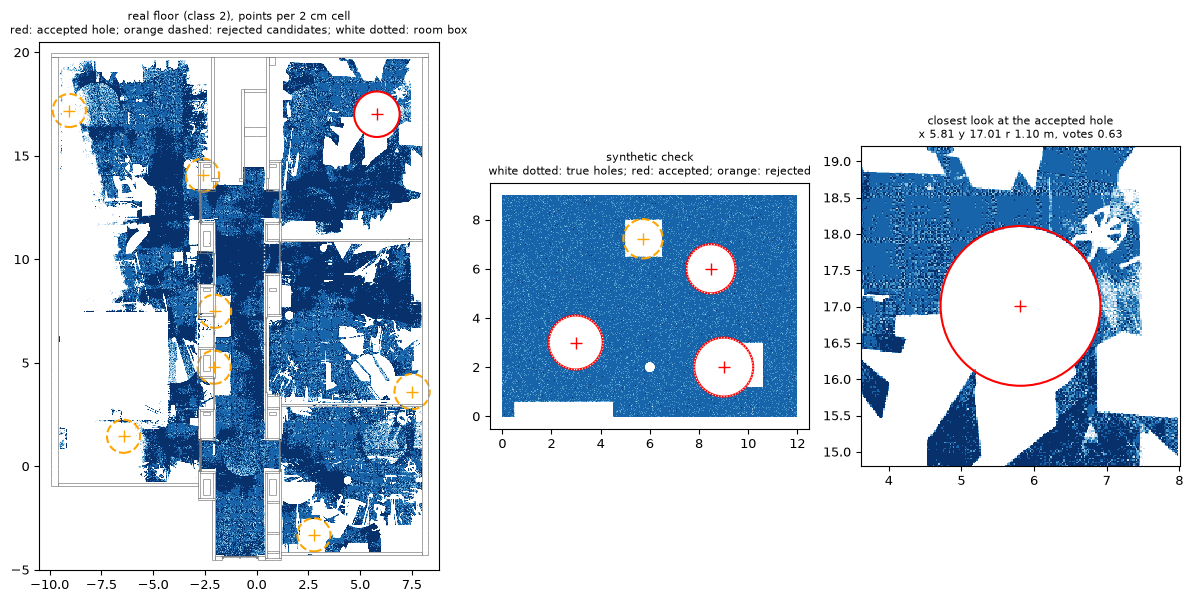

In [15]:
def show_density(ax, H, lo, extent_clip=None):
    shown = np.ma.masked_where(H == 0, np.minimum(H, 5))
    ax.imshow(shown.T, origin="lower", cmap="Blues", vmin=0, vmax=5, interpolation="nearest",
              extent=[lo[0], lo[0] + H.shape[0] * CELL, lo[1], lo[1] + H.shape[1] * CELL])


def mark(ax, c, ec, ls="-"):
    ax.add_patch(plt.Circle((c["x"], c["y"]), c["r"], fill=False, ec=ec, lw=1.5, ls=ls))
    ax.plot(c["x"], c["y"], "+", c=ec, ms=8)


fig = plt.figure(figsize=(12, 6.4))
gs = fig.add_gridspec(1, 3, width_ratios=[1.25, 1, 1])
ax = fig.add_subplot(gs[0]); show_density(ax, H_floor, lo_floor)
draw_section(ax, elements, 2, 1.15, color="0.5", lw=0.5)
for c in cand[:8]:
    if c["votes"] < ACCEPT:
        mark(ax, c, "orange", "--")
for c in accepted:
    mark(ax, c, "red")
ax.add_patch(plt.Rectangle((box_lo[0], box_lo[1]), box_hi[0] - box_lo[0], box_hi[1] - box_lo[1], fill=False, ec="w", ls=":", lw=1))
ax.set_xlim(-10.5, 8.8); ax.set_ylim(-5.0, 20.5); ax.set_aspect("equal"); ax.set_facecolor("white")
ax.set_title("real floor (class 2), points per 2 cm cell\nred: accepted hole; orange dashed: rejected candidates; white dotted: room box", fontsize=8)

ax = fig.add_subplot(gs[1]); show_density(ax, H_syn, lo_syn)
for c in cand_syn:
    mark(ax, c, "red" if c["votes"] >= ACCEPT else "orange", "-" if c["votes"] >= ACCEPT else "--")
for hx, hy, hr in TRUE_HOLES:
    ax.add_patch(plt.Circle((hx, hy), hr, fill=False, ec="w", lw=0.8, ls=":"))
ax.set_aspect("equal"); ax.set_title("synthetic check\nwhite dotted: true holes; red: accepted; orange: rejected", fontsize=8)

ax = fig.add_subplot(gs[2]); show_density(ax, H_floor, lo_floor)
if accepted:
    c = accepted[0]
    ax.set_xlim(c["x"] - 2.2, c["x"] + 2.2); ax.set_ylim(c["y"] - 2.2, c["y"] + 2.2)
    mark(ax, c, "red"); ax.set_title(f"closest look at the accepted hole\nx {c['x']:.2f} y {c['y']:.2f} r {c['r']:.2f} m, votes {c['votes']:.2f}", fontsize=8)
ax.set_aspect("equal")
plt.tight_layout(); plt.show()

In [16]:
# scanner height: not measured. Assumed here, with a consistency check from the hole's radius.
ASSUMED_HEIGHT = 1.7  # m above the floor: typical tripod + instrument centre height (assumption)
positions_model = [[c["x"], c["y"], model_floor_z + ASSUMED_HEIGHT] for c in accepted]
Tinv = np.linalg.inv(T)
positions_scan = [(Tinv[:3, :3] @ np.array(p) + Tinv[:3, 3]).round(3).tolist() for p in positions_model]
for c, p in zip(accepted, positions_model):
    half_angle = np.degrees(np.arctan2(c["r"], ASSUMED_HEIGHT))
    in_room = bool(np.all(np.array(p) >= box_lo) and np.all(np.array(p) <= box_hi))
    print(f"scanner position (model frame): x {p[0]:.2f} y {p[1]:.2f} z {p[2]:.2f} m (height assumed {ASSUMED_HEIGHT} m)")
    print(f"  hole radius {c['r']:.2f} m at that height means a blind cone of half-angle {half_angle:.0f} deg from straight down, "
          f"(a scanner with a 300 deg vertical field of view would give 30 deg) - plausible, not a measurement")
    print(f"  inside the room box: {in_room}")
N_EXPECTED = 21
scanner_answer = "no" if not accepted else "all" if len(accepted) >= N_EXPECTED else "partly"
print(f"\nSCANNER POSITIONS RECOVERED: {len(accepted)} of {N_EXPECTED} -> {scanner_answer}")
assert scanner_answer == "partly" and len(accepted) == 1  # the text below says one of 21
RESULT["scanner_positions"] = {
    "recovered": len(accepted) >= N_EXPECTED,
    "answer": scanner_answer,
    "n_found": len(accepted), "n_expected": N_EXPECTED,
    "positions_model_frame": [[round(v, 3) for v in p] for p in positions_model],
    "positions_scan_frame": positions_scan,
    "assumed_height_above_floor_m": ASSUMED_HEIGHT,
    "hole_radius_m": [round(c["r"], 2) for c in accepted],
    "vote_fraction": [round(c["votes"], 2) for c in accepted],
    "inside_room_box": [bool(np.all(np.array(p) >= box_lo) and np.all(np.array(p) <= box_hi)) for p in positions_model],
    "note": "Too few to decide line of sight: 03 treats missing vs not visible as not confirmed.",
}
print(f"peak RSS so far: {peak_rss_gb():.2f} GB")

scanner position (model frame): x 5.81 y 17.01 z 1.80 m (height assumed 1.7 m)
  hole radius 1.10 m at that height means a blind cone of half-angle 33 deg from straight down, (a scanner with a 300 deg vertical field of view would give 30 deg) - plausible, not a measurement
  inside the room box: False

SCANNER POSITIONS RECOVERED: 1 of 21 -> partly
peak RSS so far: 1.30 GB


## E. PC2Model UVigo sample (`real-indoor_modelling_3`)

This is the sample notebook 02 registers. Here: how big it is, where it sits, and what the ground-truth transform says, in particular that its scale is 1.

In [17]:
obj_path = next(UVIGO.glob("model_*.obj"))
e57_path = next(UVIGO.glob("pointcloud_*.e57"))
tf_path = next(UVIGO.glob("transformation_matrix_*.txt"))

e57 = pye57.E57(str(e57_path))  # keep a reference: the header is only valid while the file object lives
header = e57.get_header(0)
point_count = int(header.point_count)
print(f"scan: {e57.scan_count} scan, {point_count:,} points (E57 header), fields {header.point_fields}, scanner pose applied by load_e57: {header.has_pose()}")

scan_pc = load_e57(e57_path, max_points=point_count, seed=SEED)  # all points, pose applied (the scan is 230 MB as float64)
scan_pts = np.asarray(scan_pc.points)
mesh = o3d.io.read_triangle_mesh(str(obj_path))
print(f"model: OBJ, {len(mesh.vertices):,} vertices, {len(mesh.triangles):,} triangles")
bbox = lambda p: (p.min(0), p.max(0))
(smin, smax), (mmin, mmax) = bbox(scan_pts), (mesh.get_min_bound(), mesh.get_max_bound())
print(f"scan bbox   min {smin.round(1)} max {smax.round(1)}  size {(smax - smin).round(1)} m")
print(f"model bbox  min {mmin.round(1)} max {mmax.round(1)}  size {(mmax - mmin).round(1)} m")
rmin, rmax = np.percentile(scan_pts, 0.1, axis=0), np.percentile(scan_pts, 99.9, axis=0)
print(f"scan 0.1-99.9 percentile extent: {(rmax - rmin).round(1)} m (the full bbox is stretched by a few stray points, e.g. seen through windows)")

T_gt = np.loadtxt(tf_path)
print("\nground-truth 4x4 transform (as stored):")
print(np.array2string(T_gt, precision=6, suppress_small=True))
sv = np.linalg.svd(T_gt[:3, :3])[1]
det = float(np.linalg.det(T_gt[:3, :3]))
print(f"singular values of the 3x3 block: {sv}  -> scale {sv.mean():.6f} (max deviation from 1: {np.abs(sv - 1).max():.1e}); determinant {det:.6f}")
assert np.abs(sv - 1).max() < 1e-5 and abs(det - 1) < 1e-5, "ground-truth transform is not a pure rotation + translation (scale != 1)"
assert point_count == len(scan_pts) == 9_529_657

scan: 1 scan, 9,529,657 points (E57 header), fields ['cartesianX', 'cartesianY', 'cartesianZ'], scanner pose applied by load_e57: True


model: OBJ, 69,319 vertices, 79,736 triangles


scan bbox   min [-652.9   -6.2   -3.6] max [-529.4  105.   110.1]  size [123.5 111.2 113.7] m
model bbox  min [ -9.3 -20.7  -0.2] max [32.   5.9  4.3]  size [41.3 26.6  4.4] m


scan 0.1-99.9 percentile extent: [27.9 32.1 38.9] m (the full bbox is stretched by a few stray points, e.g. seen through windows)

ground-truth 4x4 transform (as stored):
[[   0.418441   -0.349979    0.838107  215.815277]
 [  -0.481263   -0.868018   -0.122189 -213.619905]
 [   0.770255   -0.352221   -0.531646  492.4662  ]
 [   0.          0.          0.          1.      ]]
singular values of the 3x3 block: [1.0000008  0.99999998 0.99999965]  -> scale 1.000000 (max deviation from 1: 8.0e-07); determinant 1.000000


[Open3D WARNING] Legacy mesh has more than 1 material which is not supported by Tensor-based mesh. Only material DefaultMaterial was converted.


scan to model distance, 300k seeded points: as stored median 562 m; after the ground-truth transform median 4.2 cm, p90 79 cm
(the long tail is probably clutter and surfaces the model leaves out; the median is the ground truth's own registration residual, about what any registration of this sample can reach)


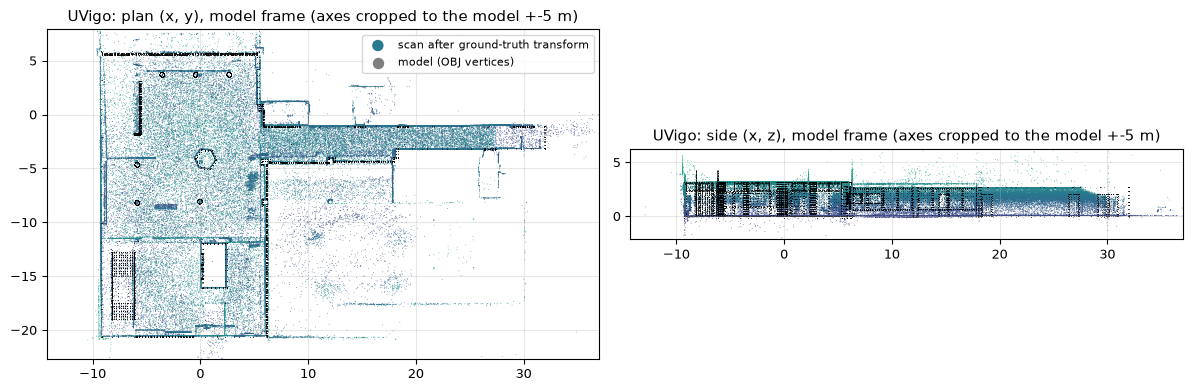

In [18]:
# which way does the matrix go? Apply it to the scan and measure the distance to the OBJ.
uv_scene = o3d.t.geometry.RaycastingScene()
uv_scene.add_triangles(o3d.t.geometry.TriangleMesh.from_legacy(mesh))
sample = scan_pts[rng.choice(len(scan_pts), 300_000, replace=False)]
sample_gt = apply(T_gt, sample)
d_gt = uv_scene.compute_distance(o3d.core.Tensor(sample_gt)).numpy()
d_raw = uv_scene.compute_distance(o3d.core.Tensor(sample.astype(np.float32))).numpy()
print(f"scan to model distance, 300k seeded points: as stored median {np.median(d_raw):.0f} m; after the ground-truth transform median {np.median(d_gt) * 100:.1f} cm, p90 {np.percentile(d_gt, 90) * 100:.0f} cm")
print("(the long tail is probably clutter and surfaces the model leaves out; the median is the ground truth's own registration residual, about what any registration of this sample can reach)")
assert np.median(d_gt) < 0.10
gt_min, gt_max = sample_gt.min(0), sample_gt.max(0)

fig, axs = plt.subplots(1, 2, figsize=(12, 5.2))
mv = np.asarray(mesh.vertices)[::3]
for ax, (a, b), name in ((axs[0], (0, 1), "plan (x, y)"), (axs[1], (0, 2), "side (x, z)")):
    sub = sample_gt[::3]
    ax.scatter(sub[:, a], sub[:, b], s=0.3, c=sub[:, 2], cmap="viridis", linewidths=0, label="scan after ground-truth transform", rasterized=True)
    ax.scatter(mv[:, a], mv[:, b], s=0.3, c="k", alpha=0.5, linewidths=0, label="model (OBJ vertices)", rasterized=True)
    ax.set_xlim(mmin[a] - 5, mmax[a] + 5); ax.set_ylim(mmin[b] - 2, mmax[b] + 2)
    ax.set_aspect("equal"); ax.set_title(f"UVigo: {name}, model frame (axes cropped to the model +-5 m)"); ax.grid(alpha=0.3)
axs[0].legend(markerscale=15, fontsize=8)
plt.tight_layout(); plt.show()

RESULT["uvigo"] = {
    "sample": UVIGO.name, "scan_point_count": point_count,
    "scan_bbox_m": [smin.tolist(), smax.tolist()], "scan_extent_p0.1_p99.9_m": (rmax - rmin).tolist(), "model_bbox_m": [mmin.tolist(), mmax.tolist()],
    "model_obj_vertices": len(mesh.vertices), "model_obj_triangles": len(mesh.triangles),
    "ground_truth_4x4_scan_to_model": T_gt.tolist(), "singular_values": sv.tolist(), "determinant": det, "scale": float(sv.mean()),
    "median_distance_after_ground_truth_m": float(np.median(d_gt)),
}
del scan_pc, scan_pts, sample, sample_gt

In [19]:
out = Path("01_cras_slice.json")
out.write_text(json.dumps(RESULT, indent=1) + "\n")
check = json.loads(out.read_text())
assert check["frame"]["answer"] == "far off" and len(check["room"]["element_global_ids"]) > 10
print(f"wrote {out} ({out.stat().st_size / 1e3:.1f} kB): keys {list(check)}")
print(f"peak RSS of this notebook: {peak_rss_gb():.2f} GB (macOS ru_maxrss), runtime {time.time() - T0:.0f} s")

wrote 01_cras_slice.json (4.3 kB): keys ['frame', 'room', 'scanner_positions', 'uvigo']
peak RSS of this notebook: 1.30 GB (macOS ru_maxrss), runtime 310 s


## Answer

**Is the CRAS scan in the model's frame?** No: **far off**. As delivered, the median distance from wall-class scan points to the model's walls is 2.68 m (25th to 75th percentile: 0.71 to 6.85 m). The scan sits about 9.8 m too far in +x, 0.43 m in +y and 1.26 m too low (scan floor at z -1.15 m, model floor at +0.10 m), and is turned by about 0.9 degrees. The shapes agree (the FFT correlation peak is 2500 against a median of 13), so this is a rigid offset, not a different building.
With the estimated rigid transform the median falls to **1.4 cm** (translation alone: 4.4 cm); 77% of wall points are within 5 cm and 52% within 1.5 cm of a model wall. That 1.4 cm is a fit residual on the same walls the transform was fitted to, with oracle labels, so it is not an accuracy statement; the 99th percentile stays near 48 cm, probably clutter labelled as wall and surfaces the model leaves out (not investigated here).
The transform is saved as `frame.scan_to_model_4x4` in `01_cras_slice.json`. Notebook 03 starts from it, as the roadmap says, and ICP-refines it.

**Which room?** Room B, box x 0.38 to 8.30, y 2.90 to 10.97, z -0.10 to 3.05 m in the model frame: 35 model elements touch it (11 walls, 1 door, 16 windows, 1 column, 5 coverings, 1 slab; 24 lie entirely inside) and it holds 3.67 M scan points (18% of the scan), of which 62% are structure classes and 25% clutter classes (the rest is unassigned). The element GlobalIds are in the JSON.

**Can the 21 scanner positions be recovered?** **Partly: 1 of 21.** The detector passes its synthetic check, and on the real floor it finds one clean round hole (radius 1.10 m, vote 0.63) at x 5.81, y 17.0 in the model frame. Nothing else scores above 0.33 (the next candidates are edges of big empty areas). My reading, untested: a floor patch left unseen by one scanner is nearly always seen by another, so the holes close up. The one that remains probably sits where no other scan looked.
That hole is in the neighbouring room C, not in room B. So in room B no scanner position is known, and notebook 03 cannot tell *missing* from *not visible* there: both become **not confirmed**. The position's height (1.70 m above the floor) is assumed, not measured. The hole radius implies a blind cone of about 33 degrees from straight down, which is in the range a 300 degree vertical field of view would give, so the assumption is plausible.
Another cue would be the radial shadows furniture casts on the floor, whose lines all point back at the scanner; not tried here.

**PC2Model UVigo.** 9 529 657 points in one scan; the scan's 0.1 to 99.9 percentile extent is 28 x 32 x 39 m (stray points stretch the full bounding box to over 100 m), the OBJ model is 69 319 vertices and 79 736 triangles across 41.3 x 26.6 x 4.4 m. The ground-truth 4x4 transform has singular values within 1e-6 of 1 and a determinant of 1.000000, so **scale = 1**: a pure rotation plus translation. Applied to the scan it brings the median scan-to-model distance from hundreds of metres to 4.2 cm.